# Data Visualization
In this section, we create the suite of visual metrics to explore resource distributions, correlations, and comparative efficiency between implementations.

In [2]:
from pathlib import Path

import json
from collections import Counter

import numpy as np
import pandas as pd

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "Data" / "Processed").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run 01_data_understanding.ipynb first to create Data/Processed.")
PROCESSED_DIR = ROOT / "Data" / "Processed"
RESULTS_DIR = ROOT / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

df_full = pd.read_parquet(PROCESSED_DIR / "validated_energy_results.parquet")
df_significant = pd.read_parquet(PROCESSED_DIR / "significant_energy_diff.parquet")
df_classified = pd.read_parquet(PROCESSED_DIR / "classified_smells.parquet")

# Positive differences mean V0 used more of the resource than V1.
df_full["energy_diff"] = df_full["result_energy_v0"] - df_full["result_energy_v1"]
df_full["runtime_diff"] = df_full["result_time_v0"] - df_full["result_time_v1"]
df_full["memory_diff"] = df_full["result_memory_v0"] - df_full["result_memory_v1"]
df_full["energy_tie"] = df_full["energy_diff"].eq(0)

metric_rows = []
for metric, column_v0, column_v1 in [
    ("energy_joules", "result_energy_v0", "result_energy_v1"),
    ("runtime_seconds", "result_time_v0", "result_time_v1"),
    ("memory_kb", "result_memory_v0", "result_memory_v1"),
]:
    values_v0, values_v1 = df_full[column_v0], df_full[column_v1]
    metric_rows.append({
        "metric": metric,
        "v0_mean": values_v0.mean(),
        "v1_mean": values_v1.mean(),
        "v0_median": values_v0.median(),
        "v1_median": values_v1.median(),
        "v1_lower_count": int((values_v1 < values_v0).sum()),
        "v0_lower_count": int((values_v0 < values_v1).sum()),
        "tie_count": int(values_v0.eq(values_v1).sum()),
    })
comparison_summary = pd.DataFrame(metric_rows)
comparison_summary.to_csv(RESULTS_DIR / "comparison_summary.csv", index=False)
display(comparison_summary)

category_counts = Counter()
if "final_classification" in df_classified.columns:
    for value in df_classified["final_classification"].dropna():
        classification = json.loads(value) if isinstance(value, str) else value
        entries = classification if isinstance(classification, list) else [classification]
        for entry in entries:
            if isinstance(entry, dict) and entry.get("category_id"):
                category_counts[entry["category_id"]] += 1
classification_summary = pd.DataFrame(
    sorted(category_counts.items()), columns=["category_id", "count"]
)
classification_summary.to_csv(RESULTS_DIR / "classification_category_counts.csv", index=False)
if not classification_summary.empty:
    display(classification_summary)

energy_ties = int(df_full["energy_tie"].sum())
print(f"Loaded {len(df_full):,} validated pairs; exact energy ties: {energy_ties:,}.")
print(f"Significant-difference source rows: {len(df_significant):,}; classified-smell rows: {len(df_classified):,}.")


,metric,v0_mean,v1_mean,v0_median,v1_median,v1_lower_count,v0_lower_count,tie_count
0,energy_joules,836.525068,639.513029,358.090000,357.190000,12698,8712,18
1,runtime_seconds,9.815829,7.758919,4.855537,4.855027,12075,9353,0
2,memory_kb,13673.072055,12784.274967,11228.000000,11224.000000,10856,10251,321


,category_id,count
0,C1,822
1,C10,601
2,C11,2
3,C12,61
4,C2,111
5,C3,1030
6,C4,88
7,C5,557
8,C6,1194
9,C7,1287


Loaded 21,428 validated pairs; exact energy ties: 18.
Significant-difference source rows: 3,000; classified-smell rows: 3,000.


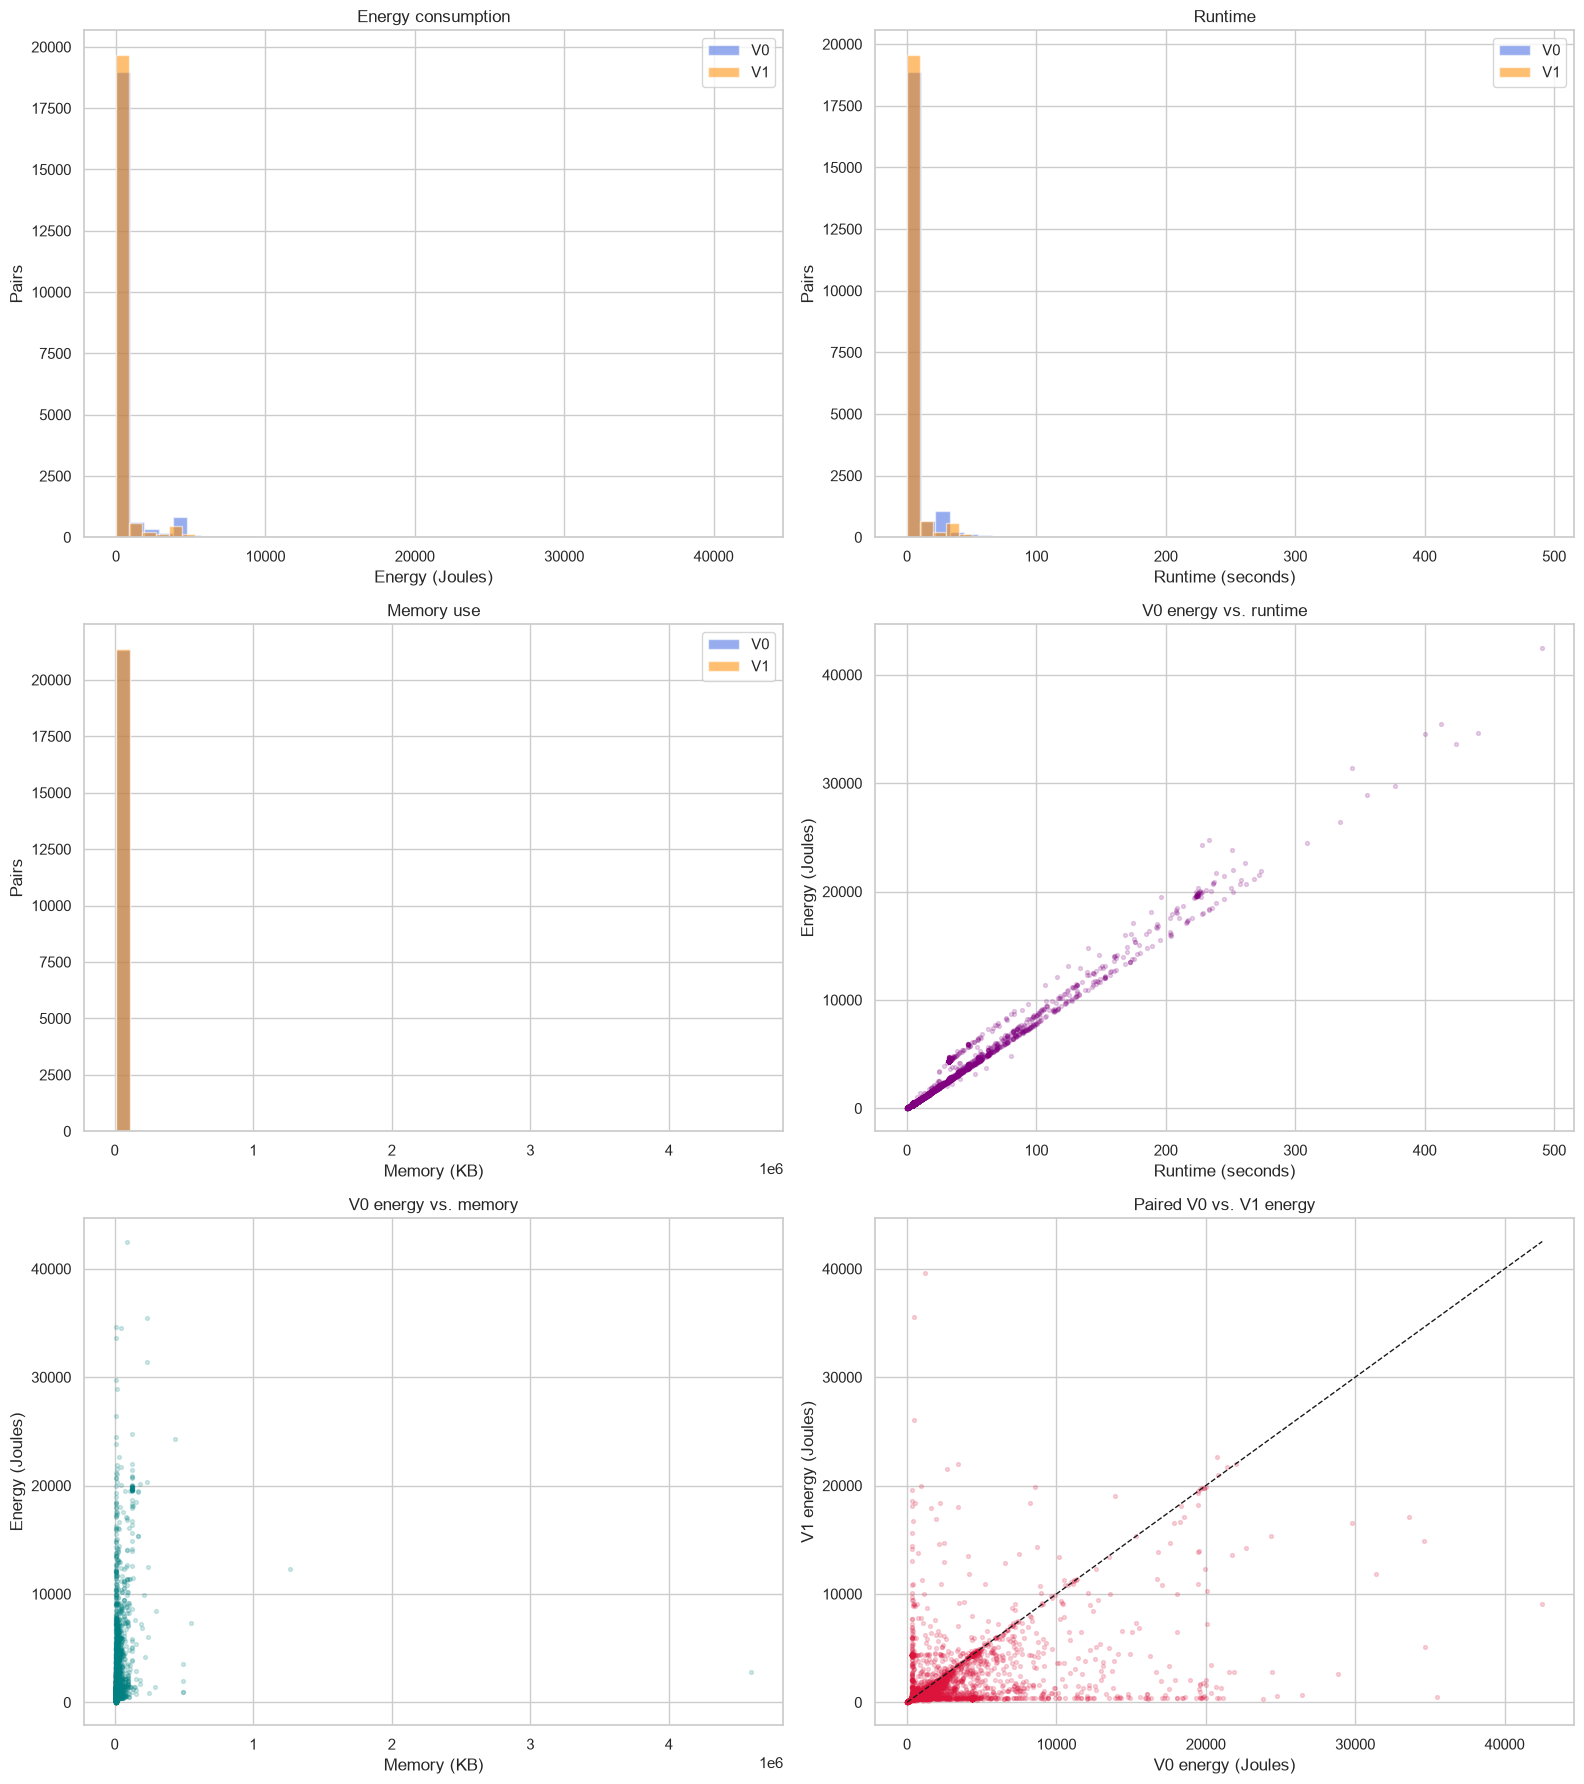

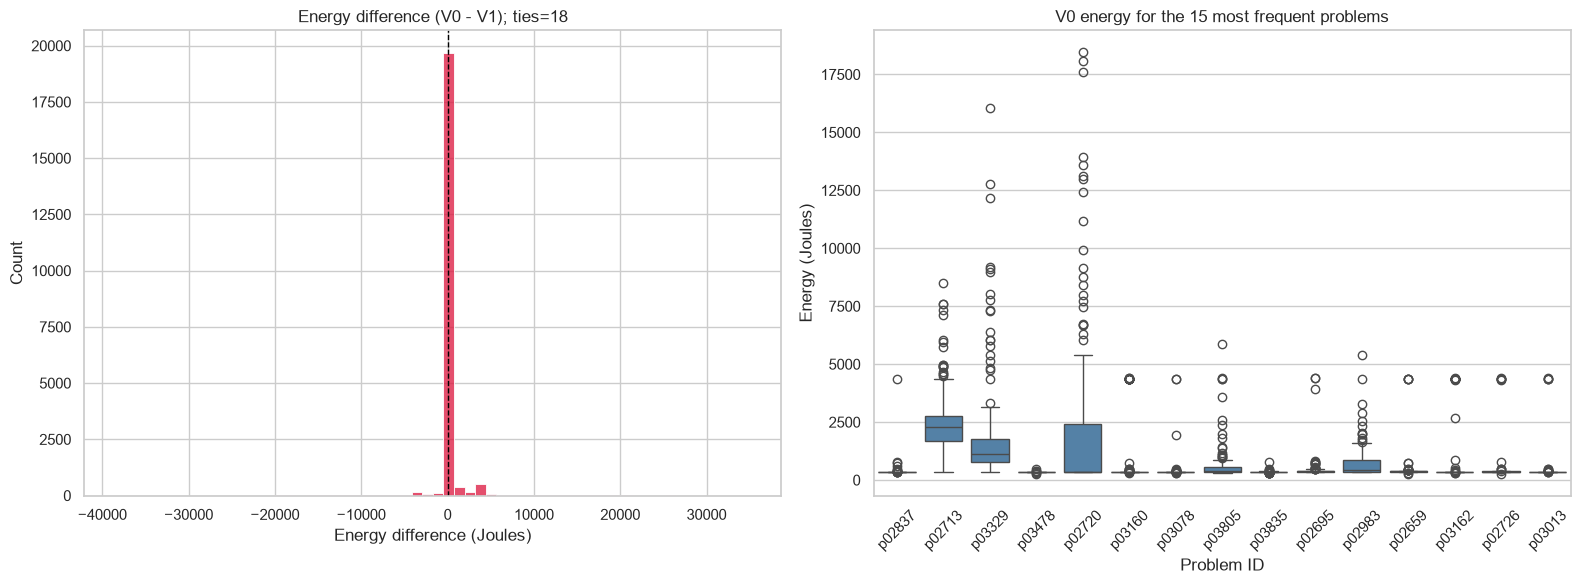

Saved figures to d:\Habiba\Uni\W26\Bachelor Thesis\energy-aware-code-recommendation\Results.


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# Paired V0/V1 distributions preserve the notebook's original comparison plots.
for ax, column_v0, column_v1, title, xlabel in [
    (axes[0, 0], "result_energy_v0", "result_energy_v1", "Energy consumption", "Energy (Joules)"),
    (axes[0, 1], "result_time_v0", "result_time_v1", "Runtime", "Runtime (seconds)"),
    (axes[1, 0], "result_memory_v0", "result_memory_v1", "Memory use", "Memory (KB)"),
]:
    ax.hist(df_full[column_v0], bins=45, alpha=0.55, label="V0", color="royalblue")
    ax.hist(df_full[column_v1], bins=45, alpha=0.55, label="V1", color="darkorange")
    ax.set(title=title, xlabel=xlabel, ylabel="Pairs")
    ax.legend()

axes[1, 1].scatter(df_full["result_time_v0"], df_full["result_energy_v0"], alpha=0.18, s=8, color="purple")
axes[1, 1].set(title="V0 energy vs. runtime", xlabel="Runtime (seconds)", ylabel="Energy (Joules)")
axes[2, 0].scatter(df_full["result_memory_v0"], df_full["result_energy_v0"], alpha=0.18, s=8, color="teal")
axes[2, 0].set(title="V0 energy vs. memory", xlabel="Memory (KB)", ylabel="Energy (Joules)")

axes[2, 1].scatter(df_full["result_energy_v0"], df_full["result_energy_v1"], alpha=0.18, s=8, color="crimson")
line_min = min(df_full["result_energy_v0"].min(), df_full["result_energy_v1"].min())
line_max = max(df_full["result_energy_v0"].max(), df_full["result_energy_v1"].max())
axes[2, 1].plot([line_min, line_max], [line_min, line_max], "k--", linewidth=1)
axes[2, 1].set(title="Paired V0 vs. V1 energy", xlabel="V0 energy (Joules)", ylabel="V1 energy (Joules)")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "resource_distributions.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(df_full["energy_diff"], bins=60, ax=axes[0], color="crimson")
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(title=f"Energy difference (V0 - V1); ties={energy_ties}", xlabel="Energy difference (Joules)")

top_problems = df_full["problem_id"].value_counts().head(15).index
top_rows = df_full[df_full["problem_id"].isin(top_problems)]
sns.boxplot(data=top_rows, x="problem_id", y="result_energy_v0", ax=axes[1], color="steelblue")
axes[1].set(title="V0 energy for the 15 most frequent problems", xlabel="Problem ID", ylabel="Energy (Joules)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "energy_differences_by_problem.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved figures to {RESULTS_DIR}.")
